In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
import io

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

# Handle original CSV if TotalCharges is still stored as text
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype(str).str.strip(),
    errors="coerce"
)

df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Dataset loaded successfully!")
print("File:", file_name)
print("Shape:", df.shape)
display(df.head())

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset loaded successfully!
File: WA_Fn-UseC_-Telco-Customer-Churn.csv
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Churn Percentage by Internet Service:


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


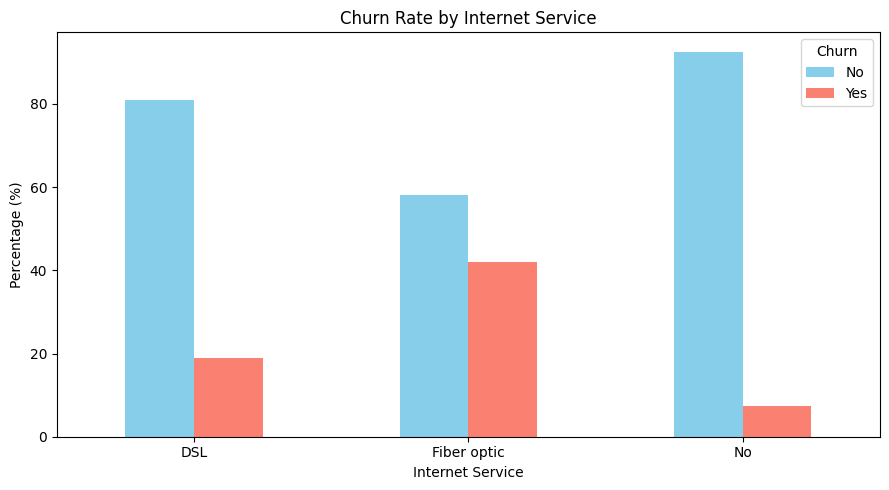

In [2]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Percentage by Internet Service:")
display(internet_churn.round(2))

internet_churn.plot(
    kind="bar",
    figsize=(9, 5),
    color=["skyblue", "salmon"]
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

Churn Percentage by Payment Method:


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


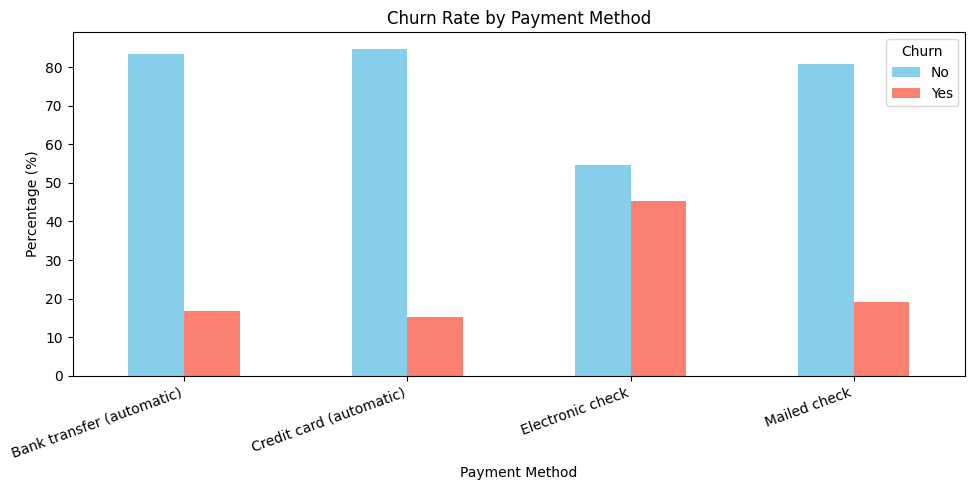

In [3]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Percentage by Payment Method:")
display(payment_churn.round(2))

payment_churn.plot(
    kind="bar",
    figsize=(10, 5),
    color=["skyblue", "salmon"]
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

Churn Percentage by Online Security:


Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


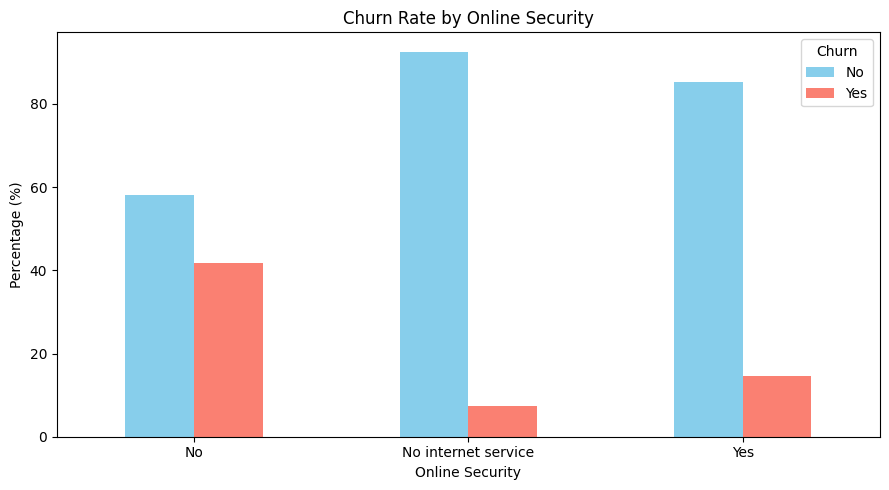

In [4]:
security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Percentage by Online Security:")
display(security_churn.round(2))

security_churn.plot(
    kind="bar",
    figsize=(9, 5),
    color=["skyblue", "salmon"]
)

plt.title("Churn Rate by Online Security")
plt.xlabel("Online Security")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

Churn Percentage by Tech Support:


Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


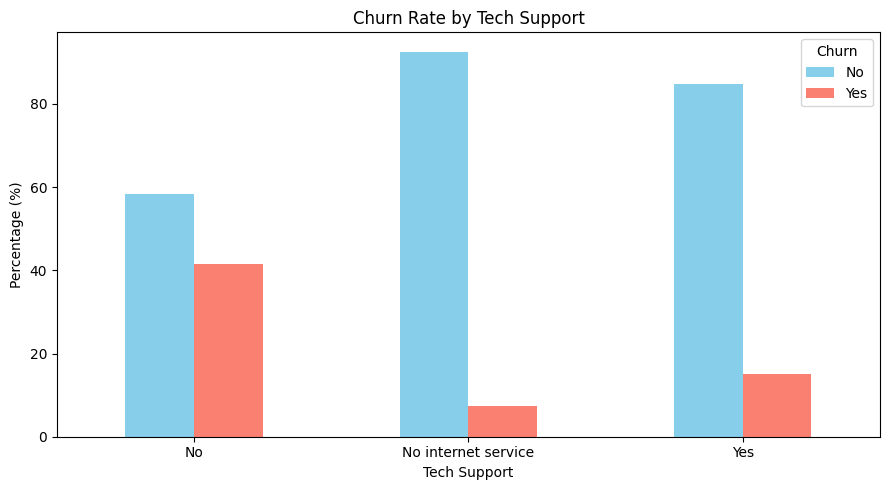

In [5]:
support_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

print("Churn Percentage by Tech Support:")
display(support_churn.round(2))

support_churn.plot(
    kind="bar",
    figsize=(9, 5),
    color=["skyblue", "salmon"]
)

plt.title("Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

Correlation Matrix:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
SeniorCitizen,1.00,0.02,0.22,0.10
tenure,0.02,1.00,0.25,0.83
MonthlyCharges,0.22,0.25,1.00,0.65
TotalCharges,0.10,0.83,0.65,1.00


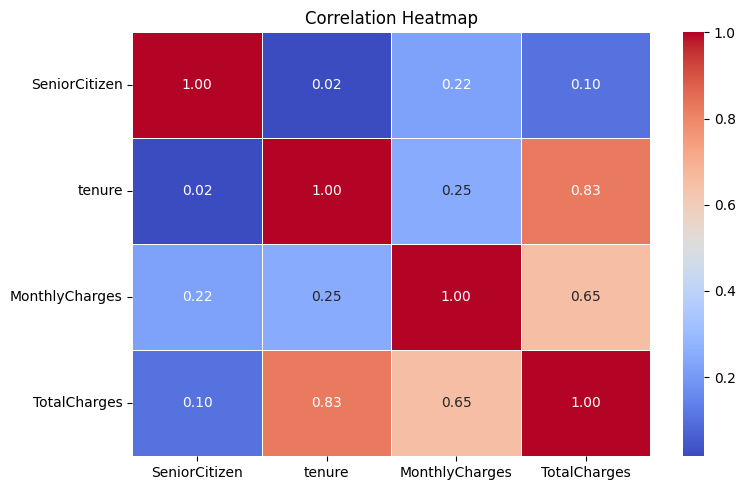

In [6]:
numerical_df = df[
    ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
]

correlation = numerical_df.corr()

print("Correlation Matrix:")
display(correlation.round(2))

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [7]:
churn_comparison = df.groupby("Churn")[
    ["tenure", "MonthlyCharges", "TotalCharges"]
].mean()

print("Average Numerical Values by Churn:")
display(churn_comparison.round(2))

Average Numerical Values by Churn:


,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2549.91
Yes,17.98,74.44,1531.80


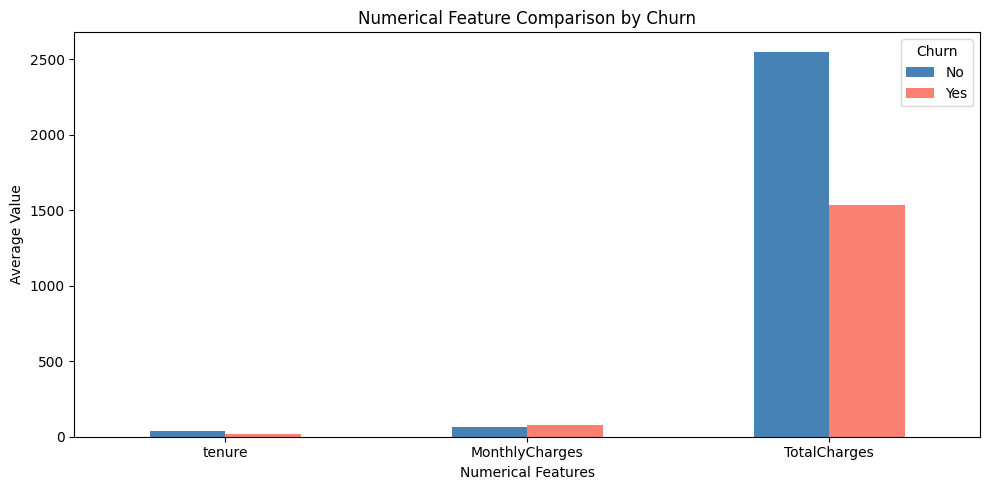

In [8]:
churn_comparison.T.plot(
    kind="bar",
    figsize=(10, 5),
    color=["steelblue", "salmon"]
)

plt.title("Numerical Feature Comparison by Churn")
plt.xlabel("Numerical Features")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [9]:
print("========== DAY 54: ADVANCED EDA INSIGHTS ==========\n")

print("1. INTERNET SERVICE")
print("Fiber optic customers have the highest churn rate: 41.89%.")

print("\n2. PAYMENT METHOD")
print("Electronic check users have the highest churn rate: 45.29%.")

print("\n3. ONLINE SECURITY")
print("Customers without Online Security have a churn rate of 41.77%,")
print("compared with 14.61% for customers with Online Security.")

print("\n4. TECH SUPPORT")
print("Customers without Tech Support have a churn rate of 41.64%,")
print("compared with 15.17% for customers with Tech Support.")

print("\n5. NUMERICAL FEATURES")
print("Churned customers have lower average tenure (17.98 months).")
print("They also have higher average monthly charges ($74.44).")

print("\n6. CORRELATION")
print("Tenure and TotalCharges have a strong positive correlation (0.83).")

print("\n===================================================")
print("Note: These are descriptive findings, not proof of causation.")

========== DAY 54: ADVANCED EDA INSIGHTS ==========

1. INTERNET SERVICE
Fiber optic customers have the highest churn rate: 41.89%.

2. PAYMENT METHOD
Electronic check users have the highest churn rate: 45.29%.

3. ONLINE SECURITY
Customers without Online Security have a churn rate of 41.77%,
compared with 14.61% for customers with Online Security.

4. TECH SUPPORT
Customers without Tech Support have a churn rate of 41.64%,
compared with 15.17% for customers with Tech Support.

5. NUMERICAL FEATURES
Churned customers have lower average tenure (17.98 months).
They also have higher average monthly charges ($74.44).

6. CORRELATION
Tenure and TotalCharges have a strong positive correlation (0.83).

Note: These are descriptive findings, not proof of causation.
